In [2]:
import pandas as pd 
import matplotlib.pyplot as plt 


In [4]:
df=pd.read_csv(r'C:\Users\user\Downloads\supermarket_sales - Sheet1.csv')
df.head(3)

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4


In [67]:
print("Boş dəyərlərin yoxlanılması:\n",df.isnull().sum())

Boş dəyərlərin yoxlanılması:
 Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64


In [68]:
print("Datadakı sətir və sütunların sayı:\n",df.shape)
print("Datadakı sütunların tipləri:\n",df.dtypes)

Datadakı sətir və sütunların sayı:
 (1000, 17)
Datadakı sütunların tipləri:
 Invoice ID                     str
Branch                         str
City                           str
Customer type                  str
Gender                         str
Product line                   str
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                           str
Time                           str
Payment                        str
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64
dtype: object


In [69]:
df['Date']=pd.to_datetime(df['Date'])
df["Time"] = pd.to_datetime(df["Time"], format="%H:%M")
df["Hour"] = pd.to_datetime(df["Time"], format="%H:%M").dt.hour
print(df[['Date','Time','Hour']].dtypes)

Date    datetime64[us]
Time    datetime64[us]
Hour             int32
dtype: object


In [6]:
df.describe().round(2)

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,55.67,5.51,15.38,322.97,307.59,4.76,15.38,6.97
std,26.49,2.92,11.71,245.89,234.18,0.00,11.71,1.72
min,10.08,1.00,0.51,10.68,10.17,4.76,0.51,4.00
25%,32.88,3.00,5.92,124.42,118.50,4.76,5.92,5.50
50%,55.23,5.00,12.09,253.85,241.76,4.76,12.09,7.00
75%,77.94,8.00,22.45,471.35,448.90,4.76,22.45,8.50
max,99.96,10.00,49.65,1042.65,993.00,4.76,49.65,10.00


In [85]:
print("Şəhərdəki sifarişlərin sayı:\n",df["City"].value_counts())

Şəhərdəki sifarişlərin sayı:
 City
Yangon       340
Mandalay     332
Naypyitaw    328
Name: count, dtype: int64


In [87]:
df.groupby(df["City"])["Rating"].mean().round(2).sort_values(ascending=False)

City
Naypyitaw    7.07
Yangon       7.03
Mandalay     6.82
Name: Rating, dtype: float64

In [89]:
print(df["Rating"].mean().round(1))

7.0


In [70]:
df.groupby("Branch").agg(
    Total_sum=('Total','sum'),
    Order_count=('Invoice ID','count')
).round().sort_values(by='Total_sum',ascending=False)

,Total_sum,Order_count
Branch,,
C,110569.0,328
A,106200.0,340
B,106198.0,332


In [71]:
margin_percentage=df.groupby("Product line").agg({
    'Total':'sum',
    'gross income':'sum'
})

margin_percentage['margin']=(margin_percentage["gross income"]/margin_percentage["Total"])*100
print(margin_percentage)

                             Total  gross income    margin
Product line                                              
Electronic accessories  54337.5315     2587.5015  4.761905
Fashion accessories     54305.8950     2585.9950  4.761905
Food and beverages      56144.8440     2673.5640  4.761905
Health and beauty       49193.7390     2342.5590  4.761905
Home and lifestyle      53861.9130     2564.8530  4.761905
Sports and travel       55122.8265     2624.8965  4.761905


In [72]:
line_total=df.groupby("Product line").agg(
    Total_sum=('Total','sum'),
    Order_count=('Invoice ID','count')
).round().sort_values(by='Total_sum',ascending=False)
print(line_total)

                        Total_sum  Order_count
Product line                                  
Food and beverages        56145.0          174
Sports and travel         55123.0          166
Electronic accessories    54338.0          170
Fashion accessories       54306.0          178
Home and lifestyle        53862.0          160
Health and beauty         49194.0          152


In [73]:
df.groupby("Customer type").agg(
    Total_sum=('Total','sum'),
    Order_count=('Invoice ID','count')
).round().sort_values(by='Total_sum',ascending=False)

,Total_sum,Order_count
Customer type,,
Member,164223.0,501
Normal,158743.0,499


In [74]:
df.groupby("Gender").agg(
    Total_sum=('Total','sum'),
    Order_count=('Invoice ID','count')
).round().sort_values(by='Total_sum',ascending=False)

,Total_sum,Order_count
Gender,,
Female,167883.0,501
Male,155084.0,499


In [75]:
hourly_total=df.groupby('Hour')['Total'].median().sort_values(ascending=False)
print(hourly_total.head(5))


Hour
19    328.7550
14    321.7725
16    290.0835
17    272.1915
13    271.2780
Name: Total, dtype: float64


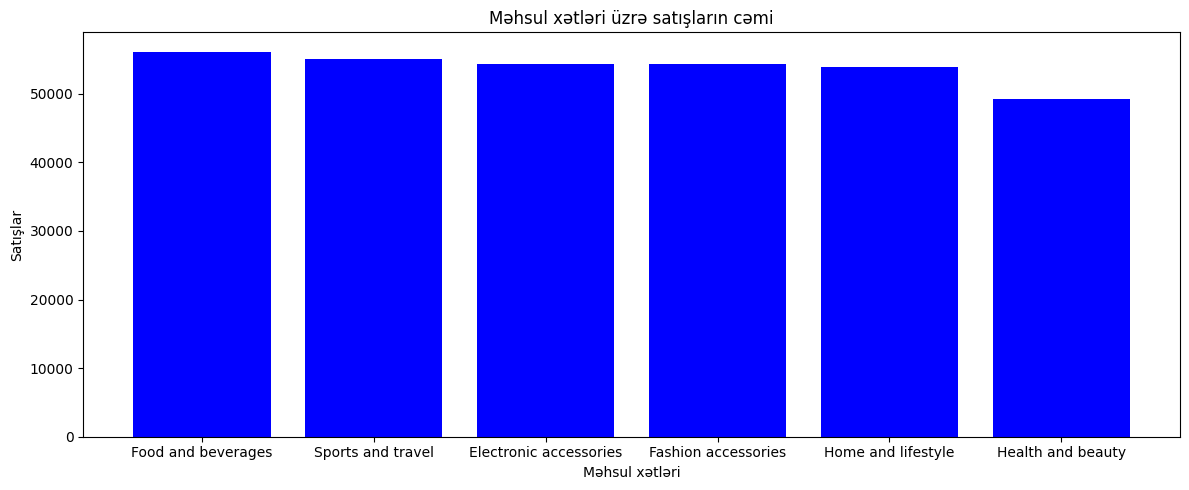

In [76]:
plt.figure(figsize=(12,5))
plt.bar(line_total.index,line_total['Total_sum'],label="Total",color="Blue")
plt.title("Məhsul xətləri üzrə satışların cəmi")
plt.xlabel("Məhsul xətləri")
plt.ylabel("Satışlar")
plt.tight_layout()
plt.show()

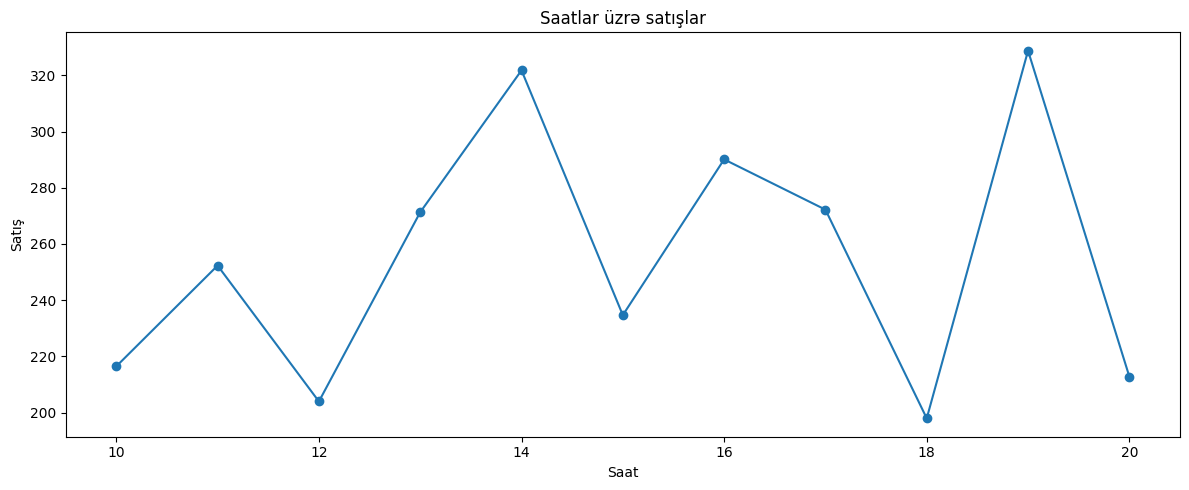

In [78]:
plt.figure(figsize=(12,5))
hourly_total = hourly_total.sort_index()
plt.plot(hourly_total.index,hourly_total.values,marker='o')
plt.title("Saatlar üzrə satışlar")
plt.xlabel("Saat")
plt.ylabel("Satış")
plt.tight_layout()
plt.show()